# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB
frame_mb = (1920 * 1080 * 3) / (1024 ** 2)

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 24 * 60 * 60

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = (1920 * 1080 * 3 * 30 * 86400 * 400) / (1024 ** 4)

# TODO 4: same fleet at 640x360 and 10 fps
fleet_tb_small = (640 * 360 * 3 * 10 * 86400 * 400) / (1024 ** 4)
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day")
print(f"Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels remaining: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day
Fleet (360p, 10 fps): 217.3 TB/day
Pixels remaining: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_ Spatial evidence lost: fine details such as faces, license plates, or small objects may become unrecognizable at lower resolution. Temporal evidence lost: brief actions or sudden movements between the 10 fps samples may never be recorded, making it difficult to reconstruct the exact sequence of events.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

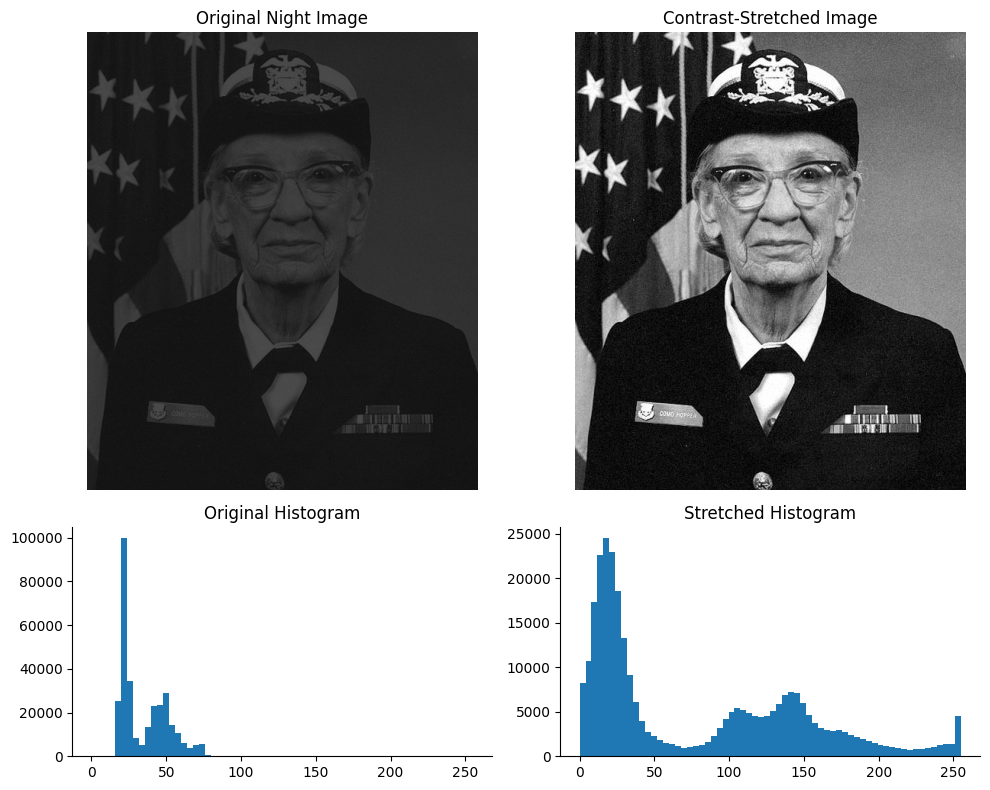

Contrast before: 0.609 -> after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast
lo, hi = np.percentile(night_still, [1, 99])
c_before = michelson(hi, lo)

# TODO 3: contrast-stretched version
stretched = np.clip(
    (night_still - lo) * 255 / (hi - lo),
    0, 255
)

lo_after, hi_after = np.percentile(stretched, [1, 99])
c_after = michelson(hi_after, lo_after)

# TODO 1 & 4: images and histograms
fig, axes = plt.subplots(2, 2, figsize=(10, 8),
                         gridspec_kw={"height_ratios": [2, 1]})

axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Night Image")
axes[0, 0].axis("off")

axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Contrast-Stretched Image")
axes[0, 1].axis("off")

axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255))
axes[1, 0].set_title("Original Histogram")

axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255))
axes[1, 1].set_title("Stretched Histogram")

plt.tight_layout()
plt.show()

print(f"Contrast before: {c_before:.3f} -> after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_ The original histogram is concentrated toward the darker intensity values, indicating an underexposed, low-contrast image. Contrast stretching spreads the occupied intensity range across 0–255, making existing details easier to distinguish without creating new information. A histogram only describes the distribution of pixel intensities, not their spatial arrangement, so it cannot identify objects or tell us what the image depicts.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing: 68.7 to 78.1 seconds
Running: 78.6 to 86.0 seconds
Audio event: 2250 at 75.0 s
Lighting event: 3000 at 100.0 s


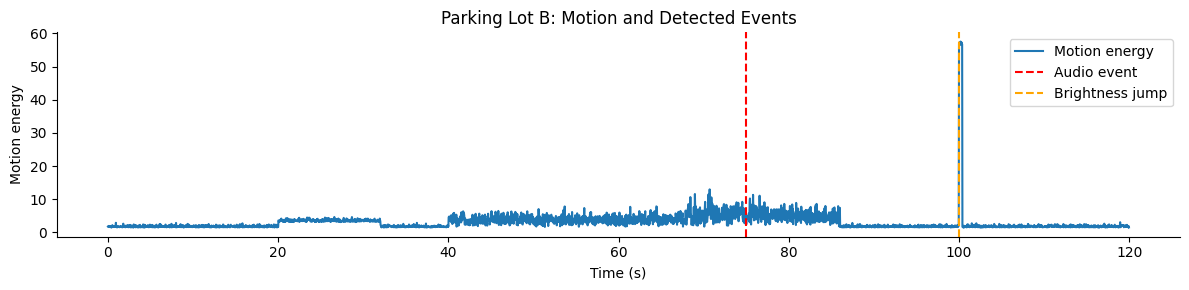

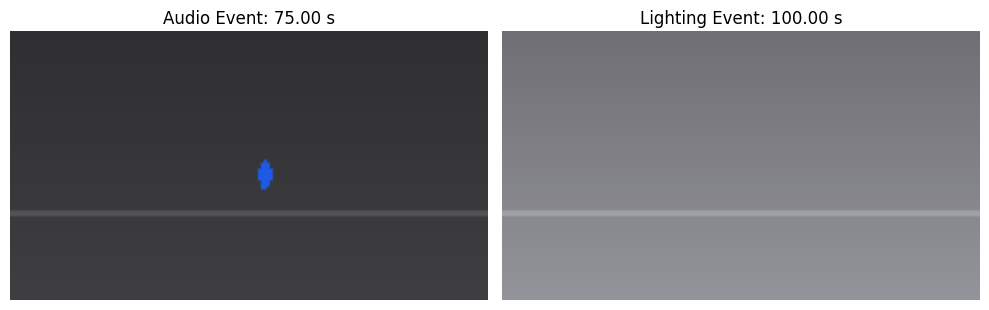

In [4]:
# TODO 1: person speed (px/s), using a 1-second window
dx = cctv["person_x"].diff(FPS)
dy = cctv["person_y"].diff(FPS)
speed = np.sqrt(dx**2 + dy**2)

# TODO 2: standing / running time ranges
standing = cctv.loc[speed < 3, "time_s"]
running = cctv.loc[speed > 25, "time_s"]

print("Standing:", standing.min(), "to", standing.max(), "seconds")
print("Running:", running.min(), "to", running.max(), "seconds")

# TODO 3: event frame indices
audio_event_idx = cctv.index[cctv["audio_level_db"] > -20][0]

brightness_jumps = cctv["mean_brightness"].diff()
lighting_event_idx = cctv.index[brightness_jumps > 40][0]

print("Audio event:", audio_event_idx,
      "at", cctv.loc[audio_event_idx, "time_s"], "s")
print("Lighting event:", lighting_event_idx,
      "at", cctv.loc[lighting_event_idx, "time_s"], "s")

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv["time_s"], cctv["motion_energy"],
        label="Motion energy")

ax.axvline(cctv.loc[audio_event_idx, "time_s"],
           color="red", linestyle="--", label="Audio event")

ax.axvline(cctv.loc[lighting_event_idx, "time_s"],
           color="orange", linestyle="--", label="Brightness jump")

ax.set_xlabel("Time (s)")
ax.set_ylabel("Motion energy")
ax.set_title("Parking Lot B: Motion and Detected Events")
ax.legend()
plt.tight_layout()
plt.show()

# TODO 5: one keyframe per event
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, idx, label in [
    (axes[0], audio_event_idx, "Audio Event"),
    (axes[1], lighting_event_idx, "Lighting Event")
]:
    ax.imshow(render_frame(cctv.iloc[idx]))
    ax.set_title(f"{label}: {cctv.loc[idx, 'time_s']:.2f} s")
    ax.axis("off")

plt.tight_layout()
plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_ Uniform keyframes taken every 20 seconds could miss the brief sound at 75 seconds and the sudden lighting change at 100 seconds. Content-based keyframe selection is more appropriate because it selects frames around meaningful changes or events instead of sampling only at fixed intervals.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

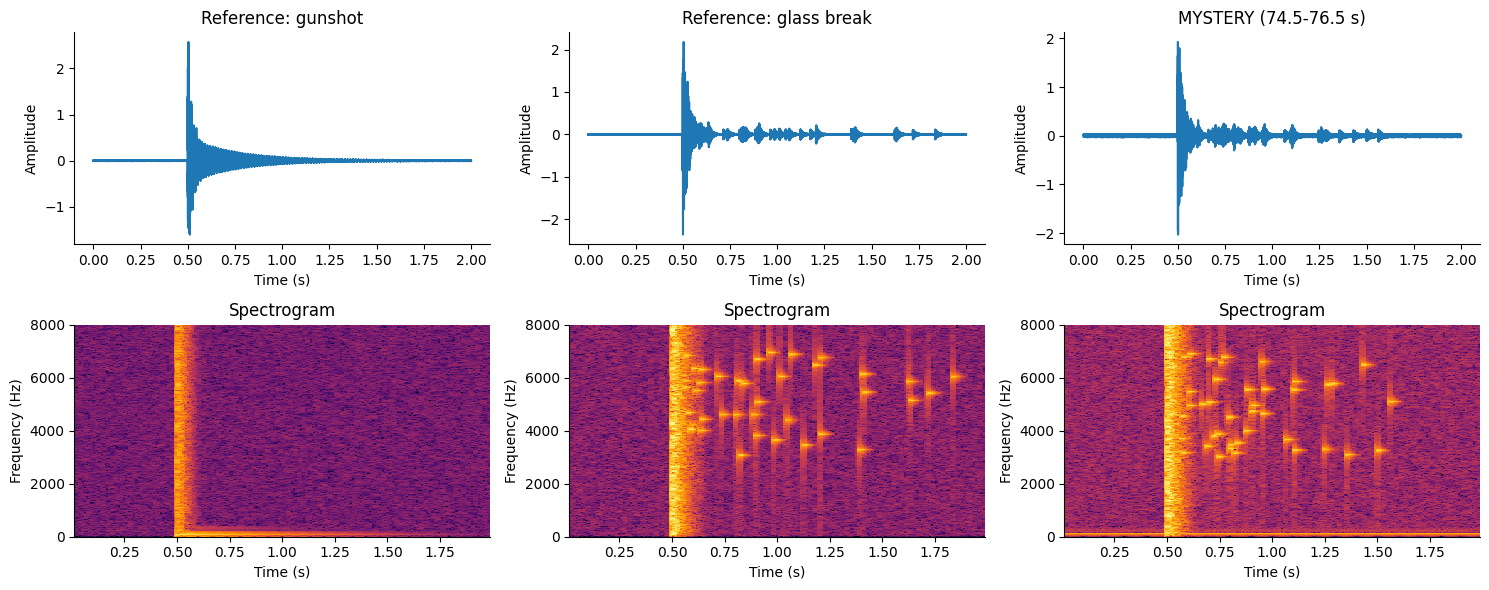

{'Reference: gunshot': np.float64(0.21543197486960136), 'Reference: glass break': np.float64(0.636765748272151), 'MYSTERY (74.5-76.5 s)': np.float64(0.6565715793025514)}
Verdict: The mystery sound is more consistent with breaking glass.


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]

clips = {
    "Reference: gunshot": ref_gunshot[1],
    "Reference: glass break": ref_glass[1],
    "MYSTERY (74.5-76.5 s)": mystery
}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))

for col, (name, x) in enumerate(clips.items()):
    t = np.arange(len(x)) / FS

    # TODO 1: waveform
    axes[0, col].plot(t, x)
    axes[0, col].set_title(name)
    axes[0, col].set_xlabel("Time (s)")
    axes[0, col].set_ylabel("Amplitude")

    # TODO 2: spectrogram
    f, ts, S = signal.spectrogram(
        x, fs=FS, nperseg=512, noverlap=384
    )

    S_db = 10 * np.log10(S + 1e-12)
    axes[1, col].pcolormesh(
        ts, f, S_db, shading="auto", cmap="inferno"
    )
    axes[1, col].set_ylim(0, 8000)
    axes[1, col].set_xlabel("Time (s)")
    axes[1, col].set_ylabel("Frequency (Hz)")
    axes[1, col].set_title("Spectrogram")

plt.tight_layout()
plt.show()

# TODO 3: fraction of spectral energy above 3 kHz
def high_frequency_fraction(x):
    # 0.2 to 1.2 seconds after the impact at 0.5 seconds
    segment = x[int(0.2 * FS):int(1.2 * FS)]

    f, ts, S = signal.spectrogram(
        segment, fs=FS, nperseg=512, noverlap=384
    )

    total_energy = S.sum()
    high_energy = S[f > 3000].sum()

    return high_energy / total_energy if total_energy > 0 else 0

hf_fraction = {
    name: high_frequency_fraction(x)
    for name, x in clips.items()
}

print(hf_fraction)

# TODO 4: verdict
gun_fraction = hf_fraction["Reference: gunshot"]
glass_fraction = hf_fraction["Reference: glass break"]
mystery_fraction = hf_fraction["MYSTERY (74.5-76.5 s)"]

if abs(mystery_fraction - glass_fraction) < abs(
    mystery_fraction - gun_fraction
):
    print("Verdict: The mystery sound is more consistent with breaking glass.")
else:
    print("Verdict: The mystery sound is more consistent with a gunshot.")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_ The three waveforms show amplitude, time, and the variation of the sound signal, but they cannot reliably distinguish a gunshot from breaking glass on their own. A spectrogram adds time, frequency, and magnitude, showing how sound energy is distributed across frequencies over time. The scattered high-frequency specks and lingering high-frequency activity in the mystery clip support the breaking-glass interpretation.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

/tmp/ipykernel_924/3805239784.py:74: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


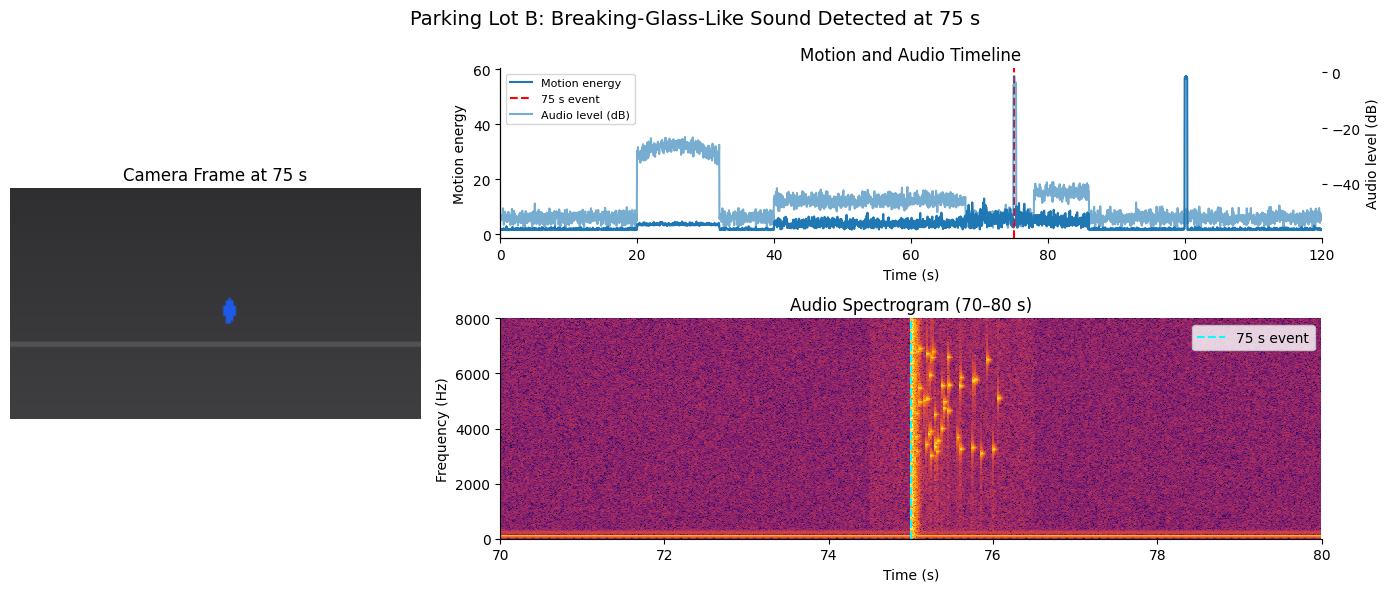

In [6]:
t_sel = 75.0

fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(
    2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3]
)

# TODO 1: rendered video frame at 75 seconds
ax_frame = fig.add_subplot(gs[:, 0])
frame_idx = (cctv["time_s"] - t_sel).abs().idxmin()

ax_frame.imshow(render_frame(cctv.iloc[frame_idx]))
ax_frame.set_title("Camera Frame at 75 s")
ax_frame.axis("off")

# TODO 2: full motion + audio timeline
ax_timeline = fig.add_subplot(gs[0, 1])

ax_timeline.plot(
    cctv["time_s"], cctv["motion_energy"],
    label="Motion energy"
)
ax_timeline.set_xlabel("Time (s)")
ax_timeline.set_ylabel("Motion energy")

ax_audio = ax_timeline.twinx()
ax_audio.plot(
    cctv["time_s"], cctv["audio_level_db"],
    alpha=0.6, label="Audio level (dB)"
)
ax_audio.set_ylabel("Audio level (dB)")

ax_timeline.axvline(
    t_sel, color="red", linestyle="--", label="75 s event"
)
ax_timeline.set_xlim(0, 120)
ax_timeline.set_title("Motion and Audio Timeline")

lines1, labels1 = ax_timeline.get_legend_handles_labels()
lines2, labels2 = ax_audio.get_legend_handles_labels()
ax_timeline.legend(lines1 + lines2, labels1 + labels2, fontsize=8)

# TODO 3: spectrogram of audio from 70 to 80 seconds
ax_spec = fig.add_subplot(gs[1, 1])

audio_mask = (t_audio >= 70) & (t_audio < 80)
audio_segment = x_audio[audio_mask]

f, ts, S = signal.spectrogram(
    audio_segment, fs=FS, nperseg=512, noverlap=384
)

S_db = 10 * np.log10(S + 1e-12)

ax_spec.pcolormesh(
    ts + 70, f, S_db, shading="auto", cmap="inferno"
)
ax_spec.axvline(
    t_sel, color="cyan", linestyle="--", label="75 s event"
)
ax_spec.set_ylim(0, 8000)
ax_spec.set_xlim(70, 80)
ax_spec.set_xlabel("Time (s)")
ax_spec.set_ylabel("Frequency (Hz)")
ax_spec.set_title("Audio Spectrogram (70–80 s)")
ax_spec.legend()

# TODO 4: conclusion-style title
fig.suptitle(
    "Parking Lot B: Breaking-Glass-Like Sound Detected at 75 s",
    fontsize=14
)

plt.tight_layout()
plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_ A +2 s audio offset could make us associate the sound with the wrong action in the video, leading to an incorrect conclusion about what happened. A synchronized timeline with a clear event marker and aligned audio/video timestamps would make the error visible.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_ The recording shows a glass-break-like sound at 75 seconds, rapid movement between 78.6 and 86 seconds, and a brightness jump at 100 seconds. A synchronized multimodal view best presents these events. Reducing routine footage to 360p at 10 fps can save storage, but important incident footage should retain enough detail to support investigations.